In [1]:
from pathlib import Path
import os 

import pandas as pd
import numpy as np
import scanpy as sc 
import matplotlib.pyplot as plt 
import matplotlib.gridspec as gridspec

from dotenv import dotenv_values
plt.rcParams["pdf.fonttype"] = 42

In [2]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Ext_Fig_01" 
os.makedirs(OUTDIR, exist_ok=True)

OBJECTS_DIR = DATADIR / "9_objects"
SC_ADATA_FP = OBJECTS_DIR / "singlecell" / "hypomap3d_singlecell_all.h5ad" 

In [3]:
adata = sc.read_h5ad(SC_ADATA_FP)

In [ ]:
scattersize = 0.05

# Metadata 

## Dataset 

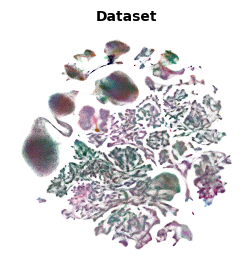

In [5]:

# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(3,3), ) 

# Pass the axis to Scanpy
sc.pl.umap(adata, color="Dataset", ax=ax, show=False, s=scattersize, legend_loc=None
)

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("Dataset", fontsize=10, fontweight="bold")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

fig.canvas.draw()

plt.savefig(OUTDIR / "umap_dataset_all.pdf", format="pdf", dpi=300, bbox_inches="tight") 

## Suspension

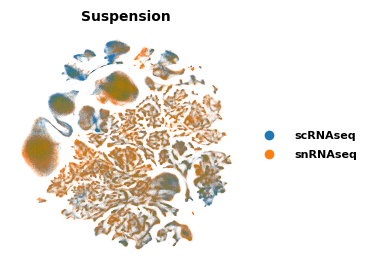

In [6]:

# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(3,3), ) 

# Pass the axis to Scanpy
sc.pl.umap(adata, color="Suspension", ax=ax, s=scattersize, show=False, 
    )

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("Suspension", fontsize=10, fontweight="bold")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

# --- Customize legend ---
leg = ax.get_legend()
if leg is not None:
    # Change font size and weight
    for text in leg.get_texts():
        text.set_fontsize(8)
        text.set_fontweight("bold")


fig.canvas.draw()


plt.savefig(OUTDIR / "Fig_ext_1b_umap_Suspension.pdf", format="pdf", dpi=300, bbox_inches="tight") 

# QC metrics

In [ ]:
adata.obs["log1p_total_counts"] = np.log1p(adata.obs.total_counts)

## log1p total counts

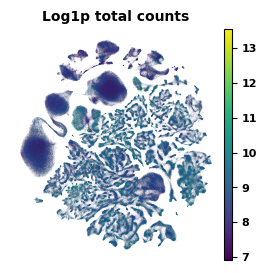

In [8]:
# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(3,3), ) 

# Pass the axis to Scanpy
sc.pl.umap(adata, color="log1p_total_counts", ax=ax, show=False, s=scattersize,
)

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("Log1p total counts", fontsize=10, fontweight="bold")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

# Make legend (colorbar) tick labels bigger and bold
# The colorbar is automatically added by Scanpy; we can access it via figure axes
for cax in fig.axes:
    if cax != ax:  # the colorbar axis
        cax.tick_params(labelsize=8)
        for label in cax.get_yticklabels():
            label.set_fontweight("bold")
        # Optionally increase colorbar label font size if exists
        if cax.get_ylabel():
            cax.set_ylabel(cax.get_ylabel(), fontsize=8, fontweight="bold")
fig.canvas.draw()


plt.savefig(OUTDIR / "umap_log1p_total_counts_all.pdf", format="pdf", dpi=300, bbox_inches="tight") 

## Num non-zero genes

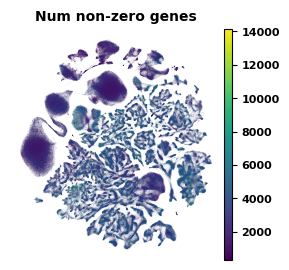

In [9]:

# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(3,3), ) 

# Pass the axis to Scanpy
sc.pl.umap(adata, color="n_genes", ax=ax, show=False, s=scattersize, 
)

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("Num non-zero genes", fontsize=10, fontweight="bold")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

# Make legend (colorbar) tick labels bigger and bold
# The colorbar is automatically added by Scanpy; we can access it via figure axes
for cax in fig.axes:
    if cax != ax:  # the colorbar axis
        cax.tick_params(labelsize=8)
        for label in cax.get_yticklabels():
            label.set_fontweight("bold")
        # Optionally increase colorbar label font size if exists
        if cax.get_ylabel():
            cax.set_ylabel(cax.get_ylabel(), fontsize=8, fontweight="bold")

fig.canvas.draw()

plt.savefig(OUTDIR / "umap_nonzero_genes_all.pdf", format="pdf", dpi=300, bbox_inches="tight") 

# Barplot

In [ ]:
color_map_novelty = {
    "Present in HypoMap (2022)": "#88B2AA",
    "Present in Allen Brain Cell Atlas": "#DDDED6",
    "New data": "#116656"
    }

In [ ]:
adata.obs["is_part_of"] = "New data"
adata.obs.loc[adata.obs.Dataset.str.contains("SC1"), "is_part_of"] = "Present in HypoMap (2022)"
adata.obs.loc[adata.obs.Author == "YaoZ", "is_part_of"] = "Present in Allen Brain Cell Atlas"

In [ ]:
ylabel_size = 23

/tmp/ipykernel_1390754/2630016673.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  author_part_counts = df.groupby(['Author', 'is_part_of']).size().unstack(fill_value=0)
/tmp/ipykernel_1390754/2630016673.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_yticklabels(ax1.get_yticklabels(), fontweight='bold')
/tmp/ipykernel_1390754/2630016673.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax1.get_xticklabels(), fontweight='bold')
/tmp/ipykernel_1390754/2630016673.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_lay

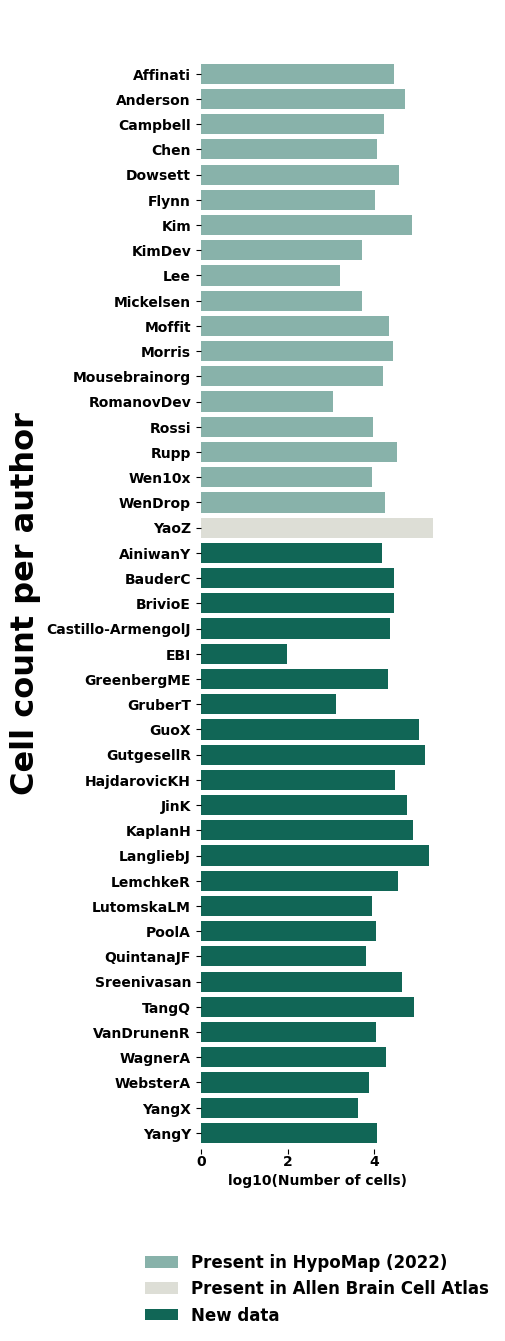

In [13]:
# --- Data Prep ---
df = adata.obs.copy()

# Author x Dataset count
author_part_counts = df.groupby(['Author', 'is_part_of']).size().unstack(fill_value=0)

def get_priority(author):
    part = df[df['Author'] == author].iloc[0]['is_part_of']
    return list(color_map_novelty.keys()).index(part) if part in color_map_novelty else 99

author_order = sorted(author_part_counts.index, key=get_priority)
author_part_counts = author_part_counts.loc[author_order]

# Composition data
is_part_counts = df['is_part_of'].value_counts(normalize=True)

# --- Plot Layout ---
fig = plt.figure(figsize=(3, 17))
gs = gridspec.GridSpec(2, 1, height_ratios=[1, 0.05], hspace=0.1, wspace=1)


# --- 1. Horizontal bar plot (log10 number of cells) ---
ax1 = plt.subplot(gs[0, 0])
bottom = np.zeros(len(author_part_counts))
for part in color_map_novelty:
    if part in author_part_counts.columns:
        log_values = np.log10(author_part_counts[part].replace(0, np.nan)).fillna(0)
        ax1.barh(author_part_counts.index, log_values, left=bottom, color=color_map_novelty[part], label=part)
        bottom += log_values
ax1.set_xlabel("log10(Number of cells)", fontweight='bold')
ax1.invert_yaxis()
handles, labels = ax1.get_legend_handles_labels()
ax1.spines["bottom"].set_position(("axes", 0.04))
ax1.set_ylabel("Cell count per author", fontweight='bold', fontsize=ylabel_size)
ax1.set_yticklabels(ax1.get_yticklabels(), fontweight='bold')
ax1.set_xticklabels(ax1.get_xticklabels(), fontweight='bold')
ax1.tick_params(axis="x", pad=0)

for spine in ax1.spines.values():
    spine.set_visible(False)


# --- Legend below figure (row 1 of GridSpec) using ax1's legend handles ---
legend_ax = plt.subplot(gs[1, 0])
legend_ax.axis('off')
legend = legend_ax.legend(handles=handles, labels=labels, loc='center', ncol=1,
                          frameon=False, fontsize='large', title=None)
#legend.set_title("Dataset", prop={'weight': 'bold'})
for txt in legend.get_texts():
    txt.set_fontweight('bold')


plt.tight_layout()

plt.savefig(OUTDIR / "ext_fig_1_count_per_author.pdf", format="pdf", dpi=300, bbox_inches="tight")